# 10 · Real image/mask folders and optional transfer learning

**Prerequisites:** lessons 08–09. **Learning time:** 90–150 minutes.

The first half runs offline: it writes a small teaching dataset to disk and uses the same loader you can adapt to your own labeled images. You will verify pairing, mask IDs, resize rules, and image-level splits before training.

The second half is **optional**: Oxford-IIIT Pet images plus pretrained LRASPP/MobileNetV3. It is disabled by default, requires internet or an existing cache, and can take substantially longer. The real-data training path is supplied for you to run; it is **not validated by the offline notebook execution**.

**Success check:** catch a missing mask or unknown class ID before training; preserve class labels while resizing; explain why a pretrained head must be adapted to your class definitions.


In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "learning" / "data.py").is_file()), None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook inside the complete ImageSegmentationPractical folder.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (10, 3.5), "image.cmap": "gray",
                     "axes.spines.top": False, "axes.spines.right": False})
print("Project:", PROJECT_ROOT.name)


Project: ImageSegmentationPractical


In [2]:
import copy
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from learning.data import make_scene, make_dataset, show_triplet, palette_mask
from learning.torch_models import ArrayDataset, PixelCNN, TinyUNet
from learning.torch_models import run_epoch, confusion_matrix, iou_from_confusion

SEED = 42
FAST_RUN = True  # False increases training; keep True for your first Run All.
torch.manual_seed(SEED)
np.random.seed(SEED)
torch.set_num_threads(2)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("All DataLoaders use num_workers=0 for a simple Windows notebook workflow.")

from PIL import Image


PyTorch: 2.11.0+cu128 | device: cuda
GPU: NVIDIA GeForce RTX 5050 Laptop GPU
All DataLoaders use num_workers=0 for a simple Windows notebook workflow.


## 1. The folder contract

Use `images/sample_001.png` with `masks/sample_001.png`. Pair by filename stem, not by independently sorting two arbitrary lists. Images may be RGB JPEG/PNG; labels must be lossless single-channel or palette-index PNG/TIFF. A colored preview is not necessarily a class-ID mask.

The demo intentionally stores IDs `0,10,20` to show that on-disk values need not match model output indices. We explicitly map them to contiguous `0,1,2`. Save your real data elsewhere; only the generated demo folder is rewritten by this lesson.


In [3]:
demo_root = PROJECT_ROOT / "artifacts" / "10_folder_demo"
for folder in ["images", "masks"]:
    (demo_root / folder).mkdir(parents=True, exist_ok=True)
demo_images, demo_masks = make_dataset(n=30, size=64, seed=300)
raw_ids = np.array([0, 10, 20], dtype=np.uint8)
for index, (image, mask) in enumerate(zip(demo_images, demo_masks)):
    name = f"scene_{index:03d}.png"
    Image.fromarray(np.round(image * 255).astype(np.uint8)).save(demo_root / "images" / name)
    Image.fromarray(raw_ids[mask]).save(demo_root / "masks" / name)
CLASS_MAP = {0: 0, 10: 1, 20: 2}
print("Generated demo only:", demo_root)


Generated demo only: C:\Users\Hareram ray\AI\ImageSegmentationPractical\artifacts\10_folder_demo


## 2. Validate the whole dataset before training

This loader rejects duplicate stems, missing pairs, size mismatches, RGB masks, unknown IDs, and empty datasets. It inspects masks **before** resizing so a tiny invalid region cannot disappear unnoticed. Palette-mode masks are read as raw indices, without converting their display colors to grayscale.

The complete implementation is visible below. For RGB-coded masks, write an explicit RGB-tuple-to-class mapping first; do not guess that grayscale conversion preserves labels.


samples: 30 image: torch.Size([3, 48, 48]) target IDs: [0, 1, 2]


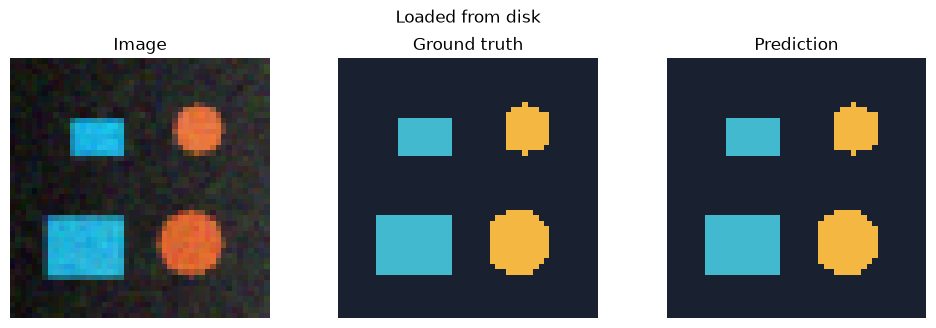

In [4]:
class FolderSegmentationDataset(Dataset):
    def __init__(self, root, class_map, size=(48, 48), classes=3, ignore_index=255):
        self.root, self.size = Path(root), size  # size is (height, width)
        self.class_map = dict(class_map)
        self.classes, self.ignore_index = classes, ignore_index
        if not self.class_map or any(v not in {*range(classes), ignore_index} for v in self.class_map.values()):
            raise ValueError("Map values must be class IDs 0..classes-1 or ignore_index")

        def by_stem(folder, allowed):
            paths = {}
            for path in sorted(folder.iterdir()):
                if not path.is_file() or path.suffix.lower() not in allowed:
                    continue
                key = path.stem.casefold()
                if key in paths:
                    raise ValueError(f"Duplicate stem in {folder}: {path.stem}")
                paths[key] = path
            return paths

        images = by_stem(self.root / "images", {".jpg", ".jpeg", ".png", ".tif", ".tiff"})
        masks = by_stem(self.root / "masks", {".png", ".tif", ".tiff"})
        if not images:
            raise ValueError("No images found")
        if images.keys() != masks.keys():
            raise ValueError(f"Unpaired files: missing masks={sorted(images.keys()-masks.keys())[:5]}, "
                             f"missing images={sorted(masks.keys()-images.keys())[:5]}")
        self.pairs = [(images[key], masks[key]) for key in sorted(images)]
        for image_path, mask_path in self.pairs:
            with Image.open(image_path) as image, Image.open(mask_path) as mask:
                raw = np.asarray(mask)
                if image.size != mask.size:
                    raise ValueError(f"Image/mask size mismatch: {image_path.name}")
                if raw.ndim != 2 or not np.issubdtype(raw.dtype, np.integer):
                    raise ValueError(f"Expected 2-D integer IDs: {mask_path.name}")
                unknown = set(np.unique(raw).tolist()) - self.class_map.keys()
                if unknown:
                    raise ValueError(f"Unknown IDs {unknown} in {mask_path.name}")

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, index):
        image_path, mask_path = self.pairs[index]
        pil_size = (self.size[1], self.size[0])
        with Image.open(image_path) as image:
            image = image.convert("RGB").resize(pil_size, Image.Resampling.BILINEAR)
            x = np.array(image, dtype=np.float32) / 255.0
        with Image.open(mask_path) as mask:
            raw = np.array(mask.resize(pil_size, Image.Resampling.NEAREST))
        y = np.full(raw.shape, self.ignore_index, dtype=np.int64)
        for raw_id, class_id in self.class_map.items():
            y[raw == raw_id] = class_id
        return torch.from_numpy(x.transpose(2, 0, 1).copy()), torch.from_numpy(y)

folder_dataset = FolderSegmentationDataset(demo_root, CLASS_MAP)
x, y = folder_dataset[0]
print("samples:", len(folder_dataset), "image:", x.shape, "target IDs:", y.unique().tolist())
assert x.dtype == torch.float32 and y.dtype == torch.long
show_triplet(x.permute(1, 2, 0).numpy(), y.numpy(), y.numpy(), title="Loaded from disk")
plt.show()


## 3. Prove a bad annotation is caught

Validation errors should describe the problem instead of silently producing a wrong model. The next cell gives a deliberately incomplete mapping, catches the expected exception, and leaves all files unchanged.


In [5]:
try:
    FolderSegmentationDataset(demo_root, {0: 0, 10: 1})
except ValueError as error:
    print("Expected validation error:", error)
else:
    raise AssertionError("The loader should reject unknown mask ID 20")


Expected validation error: Unknown IDs {20} in scene_000.png


## 4. Train the folder pipeline end to end

Nothing downstream should depend on whether samples came from memory, local folders, or a dataset library. Keep the tensor contract identical. For your own data, first visualize at least ten image/mask pairs and audit the class mapping.


In [6]:
permutation = np.random.default_rng(SEED).permutation(len(folder_dataset))
train_ids, val_ids, test_ids = permutation[:18], permutation[18:24], permutation[24:]
assert set(train_ids).isdisjoint(val_ids) and set(val_ids).isdisjoint(test_ids)
train_loader = DataLoader(Subset(folder_dataset, train_ids.tolist()), batch_size=6, shuffle=True, num_workers=0,
                          generator=torch.Generator().manual_seed(SEED))
val_loader = DataLoader(Subset(folder_dataset, val_ids.tolist()), batch_size=6, num_workers=0)
test_loader = DataLoader(Subset(folder_dataset, test_ids.tolist()), batch_size=6, num_workers=0)
torch.manual_seed(SEED)
model = PixelCNN(classes=3).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
loss_function = nn.CrossEntropyLoss(ignore_index=255)
folder_history, best_iou, best_state = [], -1.0, None
for epoch in range(8 if FAST_RUN else 40):
    train_result = run_epoch(model, train_loader, loss_function, optimizer)
    val_result = run_epoch(model, val_loader, loss_function)
    folder_history.append([train_result["loss"], val_result["loss"], val_result["miou"]])
    if val_result["miou"] > best_iou:
        best_iou = val_result["miou"]
        best_state = copy.deepcopy(model.state_dict())
model.load_state_dict(best_state)
test_result = run_epoch(model, test_loader, loss_function)
print("best validation mIoU:", round(best_iou, 3), "test mIoU:", round(test_result["miou"], 3))


C:\Users\Hareram ray\AppData\Local\Python\pythoncore-3.13-64\Lib\site-packages\triton\windows_utils.py:465: UserWarning: Failed to find CUDA. Install CUDA Toolkit (https://developer.nvidia.com/cuda-downloads) or set CUDA_HOME / CUDA_PATH environment variable.
  warnings.warn("Failed to find CUDA."


best validation mIoU: 0.94 test mIoU: 0.925


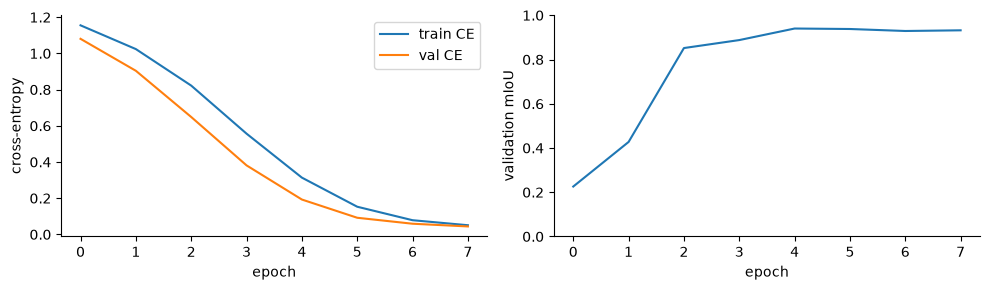

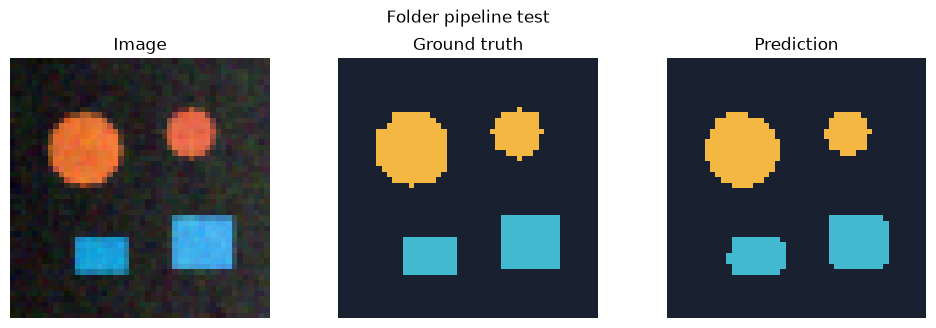

In [7]:
folder_history = np.asarray(folder_history)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(folder_history[:, 0], label="train CE"); axes[0].plot(folder_history[:, 1], label="val CE")
axes[0].legend(); axes[0].set(xlabel="epoch", ylabel="cross-entropy")
axes[1].plot(folder_history[:, 2]); axes[1].set(xlabel="epoch", ylabel="validation mIoU", ylim=(0, 1))
plt.tight_layout(); plt.show()
sample_x, sample_y = folder_dataset[int(test_ids[0])]
model.eval()
with torch.inference_mode():
    sample_prediction = model(sample_x[None].to(DEVICE)).argmax(1)[0].cpu().numpy()
show_triplet(sample_x.permute(1, 2, 0).numpy(), sample_y.numpy(), sample_prediction, title="Folder pipeline test")
plt.show()


## 5. Optional real-data project: Oxford-IIIT Pet

**Disabled by default; this section needs an intentional opt-in.** The image/annotation archive is roughly 800 MB compressed, plus extraction space and model weights. Downloads and real-data training were not run as part of offline validation. Review the [dataset's current terms and citation](https://www.robots.ox.ac.uk/~vgg/data/pets/) before your own use.

The **original archive README** defines `1=foreground`, `2=background`, `3=not classified`. Here map `1→1` (pet), `2→0` (background), `3→255` (ignore). Ignore means those uncertain pixels contribute neither loss nor IoU; it is not a third predicted class. Avoid copying label meanings from a rendered colormap.

Set `RUN_REAL_PETS=True` and `ALLOW_DOWNLOAD=True` to fetch missing resources. With `ALLOW_DOWNLOAD=False`, this section requires an already complete dataset and cached weights. Keep the official test split untouched while developing.


In [8]:
RUN_REAL_PETS = False
ALLOW_DOWNLOAD = False
real_ready = False
PET_SIZE = (128, 128)  # Small learning experiment; square resizing distorts aspect ratio.
PET_ROOT = PROJECT_ROOT / "data" / "external"
PET_RAW_TO_CLASS = {1: 1, 2: 0, 3: 255}

if RUN_REAL_PETS:
    import torchvision
    from torchvision.datasets import OxfordIIITPet
    from torchvision.models.segmentation import lraspp_mobilenet_v3_large, LRASPP_MobileNet_V3_Large_Weights
    from urllib.parse import urlparse
    weights = LRASPP_MobileNet_V3_Large_Weights.DEFAULT
    weight_cache = Path(torch.hub.get_dir()) / "checkpoints" / Path(urlparse(weights.url).path).name
    if not ALLOW_DOWNLOAD and not weight_cache.is_file():
        raise FileNotFoundError("Pretrained weights are not cached. Opt in with ALLOW_DOWNLOAD=True, then rerun.")
    pet_raw = OxfordIIITPet(PET_ROOT, split="trainval", target_types="segmentation", download=ALLOW_DOWNLOAD)
    print("torchvision:", torchvision.__version__, "trainval images:", len(pet_raw))
    real_ready = True
else:
    print("Real-data download and training skipped. The offline lesson is complete and runnable.")


Real-data download and training skipped. The offline lesson is complete and runnable.


## 6. Match the pretrained input distribution

Pretrained LRASPP expects ImageNet-style RGB normalization. We use the documented mean/std but a smaller fixed resolution for a quick training experiment; this differs from the default pretrained inference resize. Transform the mask with nearest neighbor using the **same geometric size**.

For stronger real experiments, preserve aspect ratio with paired resize/crop or padding, apply paired augmentation on training only, and retain original sizes for evaluation. The short demo below omits augmentation to make the data path easy to inspect.


In [9]:
class PetPairs(Dataset):
    def __init__(self, source, indices):
        self.source, self.indices = source, list(indices)
        self.mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
        self.std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        image, mask = self.source[int(self.indices[index])]
        raw = np.asarray(mask)
        if image.size != mask.size or raw.ndim != 2:
            raise ValueError("Pet image/mask geometry is invalid")
        if not set(np.unique(raw).tolist()) <= {1, 2, 3}:
            raise ValueError("Unexpected raw Oxford trimap IDs")
        size_wh = (PET_SIZE[1], PET_SIZE[0])
        image = np.array(image.convert("RGB").resize(size_wh, Image.Resampling.BILINEAR), dtype=np.float32) / 255
        raw = np.array(mask.resize(size_wh, Image.Resampling.NEAREST))
        target = np.full(raw.shape, 255, dtype=np.int64)
        for old_id, new_id in PET_RAW_TO_CLASS.items(): target[raw == old_id] = new_id
        x = torch.from_numpy(image.transpose(2, 0, 1).copy())
        return (x - self.mean) / self.std, torch.from_numpy(target)

if real_ready:
    pet_ids = np.random.default_rng(SEED).permutation(len(pet_raw))
    train_count, val_count = (40, 8) if FAST_RUN else (256, 64)
    pet_train_ids = pet_ids[:train_count]
    pet_val_ids = pet_ids[train_count:train_count + val_count]
    assert set(pet_train_ids).isdisjoint(pet_val_ids)
    pet_train = PetPairs(pet_raw, pet_train_ids)
    pet_val = PetPairs(pet_raw, pet_val_ids)
    pet_train_loader = DataLoader(pet_train, batch_size=2, shuffle=True, num_workers=0,
                                  generator=torch.Generator().manual_seed(SEED))
    pet_val_loader = DataLoader(pet_val, batch_size=2, num_workers=0)
    print("Optional subset train/validation:", len(pet_train), len(pet_val))
else:
    print("PetPairs defined; no real files accessed.")


PetPairs defined; no real files accessed.


## 7. Adapt the pretrained output head

The pretrained model predicts its original categories, not our binary pet/background labels. LRASPP combines low- and high-resolution branches, so replace **both** final classifiers. Freeze the backbone initially to train only the head; unfreezing later with a smaller learning rate is a separate experiment.

Keep frozen backbone batch-normalization statistics in evaluation mode. Freezing parameter gradients alone does not stop those running statistics from changing.


In [10]:
if real_ready:
    torch.manual_seed(SEED)
    pet_model = lraspp_mobilenet_v3_large(weights=weights).to(DEVICE)
    for parameter in pet_model.backbone.parameters(): parameter.requires_grad_(False)
    low_channels = pet_model.classifier.low_classifier.in_channels
    high_channels = pet_model.classifier.high_classifier.in_channels
    pet_model.classifier.low_classifier = nn.Conv2d(low_channels, 2, 1).to(DEVICE)
    pet_model.classifier.high_classifier = nn.Conv2d(high_channels, 2, 1).to(DEVICE)
    pet_optimizer = torch.optim.Adam([p for p in pet_model.parameters() if p.requires_grad], lr=1e-3)
    pet_criterion = nn.CrossEntropyLoss(ignore_index=255)
    pet_model.eval()
    with torch.inference_mode():
        shape_check = pet_model(pet_train[0][0][None].to(DEVICE))["out"]
    assert shape_check.shape == (1, 2, *PET_SIZE)
    print("Adapted output:", tuple(shape_check.shape))
else:
    print("Pretrained model construction skipped; no weights downloaded.")


Pretrained model construction skipped; no weights downloaded.


## 8. Run an actual short fine-tuning/evaluation loop

The quick option trains four batches per epoch. This is a pipeline check, not a benchmark. Validation aggregates only labeled pixels, and the best validation state is restored. Increase data and training only after inspecting image/mask overlays. This path runs only when the explicit opt-in above succeeded.


In [11]:
def pet_epoch(model, loader, optimizer=None, max_batches=None):
    model.train(optimizer is not None)
    model.backbone.eval()  # Frozen features: also freeze BatchNorm running statistics.
    matrix = torch.zeros(2, 2, dtype=torch.int64)
    loss_sum, valid_pixels = 0.0, 0
    with torch.set_grad_enabled(optimizer is not None):
        for batch_index, (x, y) in enumerate(loader):
            if max_batches is not None and batch_index >= max_batches: break
            x, y = x.to(DEVICE), y.to(DEVICE)
            labeled = (y != 255).sum().item()
            if labeled == 0: continue
            output = model(x)["out"]
            loss = pet_criterion(output, y)
            if optimizer is not None:
                optimizer.zero_grad(set_to_none=True); loss.backward(); optimizer.step()
            loss_sum += loss.item() * labeled
            valid_pixels += labeled
            matrix += confusion_matrix(output.detach().argmax(1), y, 2, ignore_index=255)
    if valid_pixels == 0: raise ValueError("No labeled pixels were evaluated")
    iou = iou_from_confusion(matrix)
    return loss_sum / valid_pixels, float(torch.nanmean(iou)), iou.numpy()

if real_ready:
    best_pet_iou, best_pet_state, pet_history = -1.0, None, []
    for epoch in range(2 if FAST_RUN else 10):
        train_stats = pet_epoch(pet_model, pet_train_loader, pet_optimizer, 4 if FAST_RUN else None)
        val_stats = pet_epoch(pet_model, pet_val_loader)
        pet_history.append([train_stats[0], val_stats[0], val_stats[1]])
        if val_stats[1] > best_pet_iou:
            best_pet_iou, best_pet_state = val_stats[1], copy.deepcopy(pet_model.state_dict())
        print(f"pet epoch {epoch+1}: train CE={train_stats[0]:.3f}, val mIoU={val_stats[1]:.3f}")
    pet_model.load_state_dict(best_pet_state); pet_model.eval()
    px, py = pet_val[0]
    with torch.inference_mode(): pp = pet_model(px[None].to(DEVICE))["out"].argmax(1)[0].cpu().numpy()
    restored_rgb = (px * pet_val.std + pet_val.mean).permute(1, 2, 0).numpy().clip(0, 1)
    fig, axes = plt.subplots(1, 3, figsize=(10, 3))
    axes[0].imshow(restored_rgb); axes[0].set_title("Real pet")
    axes[1].imshow(np.ma.masked_equal(py.numpy(), 255), vmin=0, vmax=1); axes[1].set_title("Target: ignored pixels masked")
    axes[2].imshow(pp, vmin=0, vmax=1); axes[2].set_title("Adapted prediction")
    for ax in axes: ax.axis("off")
    plt.tight_layout(); plt.show()
else:
    print("Optional real-data fine-tuning and evaluation skipped.")


Optional real-data fine-tuning and evaluation skipped.


## Experiment 1 · Adapt this to your own folders

Copy the folder convention, point a **new** `FolderSegmentationDataset` to your root, and write the raw-to-contiguous class map. Do not change the generated demo path into your real-data directory. Visualize random samples before training.

<details><summary>Worked solution 1</summary>

For masks with `0=background`, `128=road`, `255=unknown`, use `{0:0,128:1,255:255}`, `classes=2`, and a two-channel model. Keep `CrossEntropyLoss(ignore_index=255)` and exclude ignored pixels from metrics. Audit whether 255 really means unknown in **your** annotation specification; many binary masks use 255 for foreground.
</details>


## Experiment 2 · Test the filename contract

In a separate copy of the demo, rename one mask and explain the error. Add a same-stem `.jpg` and `.png` image to test duplicate detection. Why could independently sorted image and mask lists silently train on the wrong targets?

<details><summary>Worked solution 2</summary>

One missing file shifts list positions, so `zip(sorted(images), sorted(masks))` can pair unrelated samples and silently discard unmatched tail items. Pairing by stem and checking identical key sets prevents that. Duplicate extensions with one stem are ambiguous and should fail instead of picking one arbitrarily.
</details>


## Experiment 3 · Expand the real-data experiment carefully

After the optional quick run works, compare a frozen backbone with partial fine-tuning using the **same** validation images. Keep a separate official test evaluation for the end. Specify which pixels are ignored and which classes are averaged.

<details><summary>Worked solution 3</summary>

First set `FAST_RUN=False` and record a frozen-backbone baseline. In a separate run, unfreeze selected late backbone layers, use a smaller learning rate (for example `1e-4`), and decide explicitly whether BatchNorm should update. Keep preprocessing and split IDs fixed, save the best validation state, and inspect per-class IoU. A tiny subset is for debugging; a meaningful comparison needs broader data and repeated seeds.
</details>


## Checkpoint and common errors

- Detect unpaired files, duplicate stems, wrong spatial size, and unknown mask IDs.
- Recognize a visualization mask versus raw class IDs; never use JPEG labels.
- Avoid independent random crops/flips for images and masks.
- Expect torchvision models to return a dictionary; segmentation logits are under `["out"]`.
- An unavailable optional cache is not an offline notebook failure; keep `RUN_REAL_PETS=False` until ready.
- A model's original class names do not automatically match your annotation taxonomy.

## References

- [Oxford-IIIT Pet dataset](https://www.robots.ox.ac.uk/~vgg/data/pets/) and the `annotations/README` inside its [official annotations archive](https://www.robots.ox.ac.uk/~vgg/data/pets/data/annotations.tar.gz) for raw ID semantics.
- [Torchvision OxfordIIITPet source and split API](https://docs.pytorch.org/vision/stable/_modules/torchvision/datasets/oxford_iiit_pet.html)
- [Torchvision LRASPP weights and preprocessing](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.segmentation.lraspp_mobilenet_v3_large.html)

Continue to lesson 11 for instance segmentation, or lesson 12 for loss choices, tiled prediction, and an end-to-end capstone.
